In [1]:
import tensorflow
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import fashion_mnist

(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

print(X_train.shape, y_train.shape)

c:\Users\Edward\Desktop\python\Lib\site-packages\google\api_core\_python_version_support.py:263: FutureWarning: You are using a Python version (3.11.9) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


(60000, 28, 28) (60000,)


## Preprocessing

In [2]:
# scaling
X_train_scaled = X_train / 255.0
X_test_scaled = X_test / 255.0

# Conv layer required channels
X_train_scaled = X_train_scaled.reshape(-1, 28, 28, 1)
X_test_scaled = X_test_scaled.reshape(-1, 28, 28, 1)

print(X_train_scaled.shape)
print(X_test_scaled.shape)

(60000, 28, 28, 1)
(10000, 28, 28, 1)


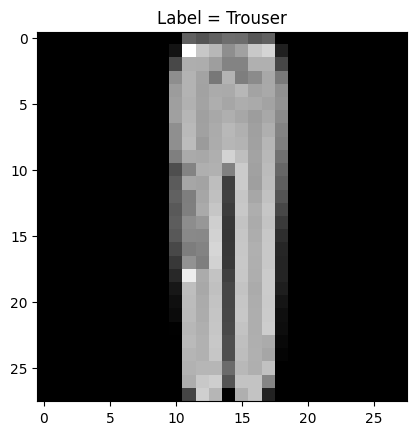

In [3]:
label = {0:'T-shirt/Top',
         1:'Trouser',
         2:'Pullover',
         3:'Dress',
         4:'Coat',
         5:'Sandal',
         6:'Shirt',
         7:'Sneaker',
         8:'Bag',
         9:'Ankle Boot'}

plt.imshow(X_train[1000], cmap='gray')
plt.title(f'Label = {label[y_train[1000]]}')
plt.show()

## CNN

In [4]:
from tensorflow.keras import layers, Sequential

# CNN: Conv(32) -> Pool -> Conv(64) -> Pool -> Flatten -> Dense(10)
cnn_model = Sequential([

    layers.Conv2D(filters=32, kernel_size=(3,3), activation='relu',
                  input_shape=(X_train_scaled.shape[1], X_train_scaled.shape[2], X_train_scaled.shape[3])),
    layers.MaxPooling2D(pool_size=(2,2)),

    layers.Conv2D(filters=64, kernel_size=(3,3), activation='relu'),

    layers.MaxPooling2D(pool_size=(2,2)),

    layers.Flatten(),

    layers.Dense(units=10, activation='softmax')
])

c:\Users\Edward\Desktop\python\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [5]:
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        16,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,826 (136.04 KB)

 Trainable params: 34,826 (136.04 KB)

 Non-trainable params: 0 (0.00 B)

## compile and fit

In [6]:
cnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy', # y is plain int labels (0-9)
    metrics=['accuracy']
)

cnn_history = cnn_model.fit(
    X_train_scaled, y_train,
    epochs = 10,
    batch_size = 64,
    validation_split=0.1
)


Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.8079 - loss: 0.5408 - val_accuracy: 0.8643 - val_loss: 0.3857
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8713 - loss: 0.3608 - val_accuracy: 0.8853 - val_loss: 0.3299
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8879 - loss: 0.3168 - val_accuracy: 0.8855 - val_loss: 0.3182
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8954 - loss: 0.2921 - val_accuracy: 0.8868 - val_loss: 0.3147
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9029 - loss: 0.2707 - val_accuracy: 0.8923 - val_loss: 0.2932
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9099 - loss: 0.2524 - val_accuracy: 0.9002 - val_loss: 0.2724
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9148 - loss: 0.2359 - val_accuracy: 0.9025 - val_loss: 0.2743
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9193 - loss: 0.2238 - val_accuracy: 0.

## training vs validation asccuracy and loss

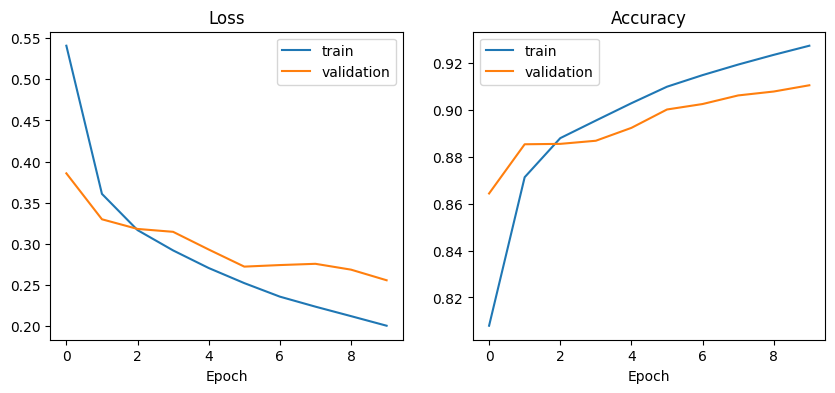

In [7]:
import matplotlib.pyplot as plt

h = cnn_history.history          # dict: loss, accuracy, val_loss, val_accuracy

fig, ax = plt.subplots(1, 2, figsize=(10, 4))   # two plots side by side

ax[0].plot(h['loss'], label='train')
ax[0].plot(h['val_loss'], label='validation')
ax[0].set_title('Loss')
ax[0].set_xlabel('Epoch')
ax[0].legend()

ax[1].plot(h['accuracy'], label='train')
ax[1].plot(h['val_accuracy'], label='validation')
ax[1].set_title('Accuracy')
ax[1].set_xlabel('Epoch')
ax[1].legend()

plt.show()

## early stopping

In [9]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

cnn_model_v2 = Sequential([
    layers.Conv2D(filters=32, kernel_size=(3,3), activation='relu', input_shape=(28,28,1)),
    layers.MaxPooling2D(pool_size=(2,2)),
    layers.Conv2D(filters=64, kernel_size=(3,3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2,2)),
    layers.Flatten(),
    layers.Dense(units=10, activation='softmax')
])

cnn_model_v2.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cnn_history_v2 = cnn_model_v2.fit(
    X_train_scaled, y_train,
    epochs = 15,
    batch_size = 64,
    validation_split=0.1,
    callbacks=[early_stop]
)


Epoch 1/15


c:\Users\Edward\Desktop\python\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.8030 - loss: 0.5506 - val_accuracy: 0.8578 - val_loss: 0.3874
Epoch 2/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8735 - loss: 0.3589 - val_accuracy: 0.8758 - val_loss: 0.3377
Epoch 3/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8861 - loss: 0.3168 - val_accuracy: 0.8835 - val_loss: 0.3183
Epoch 4/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.8956 - loss: 0.2912 - val_accuracy: 0.8862 - val_loss: 0.3096
Epoch 5/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9030 - loss: 0.2682 - val_accuracy: 0.9025 - val_loss: 0.2735
Epoch 6/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9093 - loss: 0.2508 - val_accuracy: 0.9002 - val_loss: 0.2748
Epoch 7/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9144 - loss: 0.2369 - val_accuracy: 0.9058 - val_loss: 0.2587
Epoch 8/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9198 - loss: 0.2218 - val_accuracy: 0.9050 - val_

## evaluate on test set

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

# 1) one-time test score
test_loss, test_acc = cnn_model_v2.evaluate(X_test_scaled, y_test)
print(test_loss, test_acc)

# 2) predictions
probs = cnn_model_v2.predict(X_test_scaled)  # shape (10000, 10)
y_pred = probs.argmax(axis=1)  # one class per image, picks the highest probability
# axis 1 runs across the columns, which are the 10 classes.

# 3) per-class results
names = [label[i] for i in range(10)]  #dict, in label order
print(classification_report(y_test, y_pred, target_names=names))
print(confusion_matrix(y_test, y_pred)) #The diagonal counts correct predictions, anything off diagonal are wrong predictions

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9003 - loss: 0.2748
0.2748109996318817 0.9003000259399414
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
              precision    recall  f1-score   support

 T-shirt/Top       0.87      0.82      0.84      1000
     Trouser       1.00      0.98      0.99      1000
    Pullover       0.77      0.91      0.83      1000
       Dress       0.92      0.91      0.91      1000
        Coat       0.88      0.80      0.84      1000
      Sandal       0.98      0.97      0.98      1000
       Shirt       0.73      0.70      0.71      1000
     Sneaker       0.95      0.97      0.96      1000
         Bag       0.96      0.98      0.97      1000
  Ankle Boot       0.97      0.96      0.97      1000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000

[[821   0  30  18   2   1 120   0   8   0]
 [  2 980   2  10   2   0   3   0   1   0]
 

114


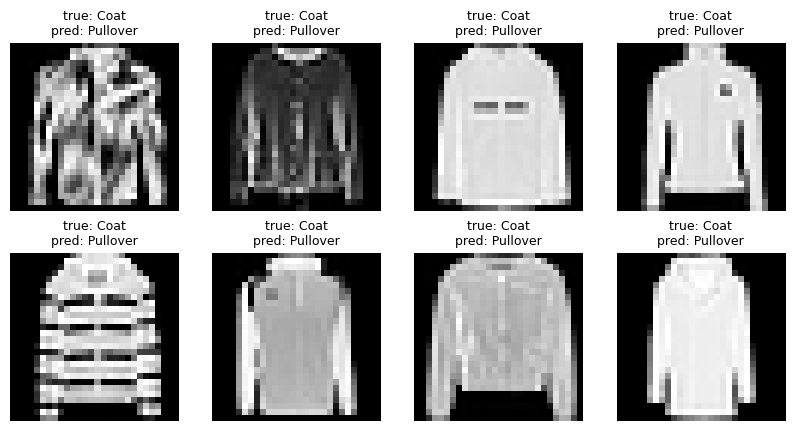

In [ ]:
import numpy as np

idx = np.where((y_test == 4) & (y_pred == 2))[0]   # true Coat, predicted Pullover
print(len(idx))  # should be 114

fig, ax = plt.subplots(2, 4, figsize=(10, 5))
for a, i in zip(ax.flat, idx[:8]):
    a.imshow(X_test[i], cmap='gray')
    a.set_title(f'true: {label[y_test[i]]}\npred: {label[y_pred[i]]}', fontsize=9)
    a.axis('off')
plt.show()